In [1]:
# geopandas 多图像绘制
# 完成时间：2026-7-14
# 练习内容：以出租车 GPS 轨迹数据为例，覆盖了从数据预处理到三种热力图实现的完整流程

数据集计处理

In [2]:
# 绘制数据分布的时候，首先第一步还是得将数据集计，得到每一个小范围内的数据量是多少。这里采用的是经纬度小数点保留三位小数
import pandas as pd
# 读取数据
data = pd.read_csv(r'E:\GIS_Learning\data\TaxiData-Sample',header = None) # header=None 告诉pandas这个文件没有表头行
# 给数据命名列
data.columns = ['VehicleNum', 'Stime', 'Lng', 'Lat', 'OpenStatus', 'Speed']

In [3]:
# 筛选范围内数据
bounds = [113.7, 22.42, 114.3, 22.8] # [最小经度，最小纬度，最大经度，最大纬度]（西、南、东、北）
data = data[(data['Lng']>bounds[0])&(data['Lng']<bounds[2])&(data['Lat']>bounds[1])&(data['Lat']<bounds[3])] # 保留同时满足这四条件的数据

In [4]:
# 经纬度小数点保留三位小数
data2 = data[['Lng','Lat']].round(3).copy() # 先提取经度|纬度两列 .round(3)：四舍五入保留3位小数 .copy()生成副本避免篡改元数据报错

# 集计每个小范围内数据量
data2['count'] = 1 # 新增一列`count`，所有行的取值都为 1。每一行对应一个 GPS 点位，方便后续分组计数
data2 = data2.groupby(['Lng','Lat'])['count'].count().reset_index() # .groupby按经度、纬度两列进行分组，所有经纬度相同的行会被归为一组

# 排序数据，让数据量小的放上面先画，数据大的放下面最后画
data2.sort_values(by = 'count') # 按count列的数值从小到大排序


data2.head(5)

,Lng,Lat,count
0,113.701,22.779,1
1,113.703,22.779,1
2,113.715,22.781,1
3,113.717,22.780,1
4,113.723,22.769,1


散点图绘制

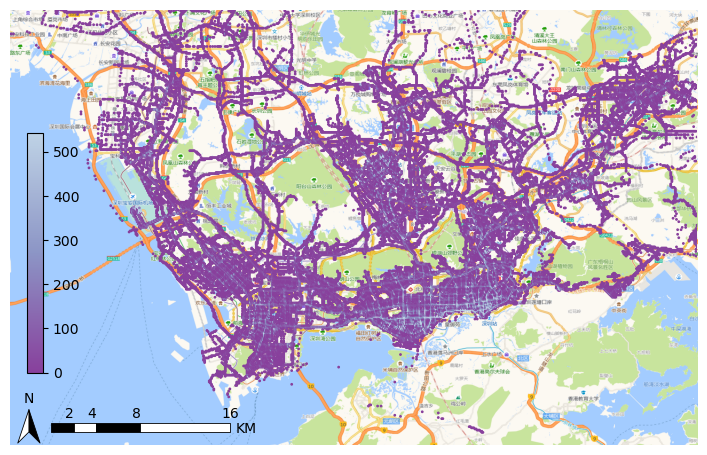

In [5]:
bounds = [113.7, 22.42, 114.3, 22.8]

import matplotlib as mpl
import matplotlib.pyplot as plt
import plot_map
import seaborn as sns
fig     = plt.figure(1,(8,8),dpi = 100)    
ax      = plt.subplot(111)
plt.sca(ax)
fig.tight_layout(rect = (0.05,0.1,1,0.9))

# 背景
plot_map.plot_map(plt,bounds,zoom = 12,style = 4)


# colorbar
pallete_name = "BuPu"

# 从 seaborn 配色库中提取指定数量的基础颜色
colors = sns.color_palette(pallete_name, 3) 
# sns.color\_palette():获取 / 生成配色方案，返回值是一个由 RGB 颜色元组组成的列表（每个元素是 (r, g, b)格式，数值为 0~1 之间的浮点数）
# seaborn 内置了大量成熟的配色方案，比如单色系渐变 Purples/Blues、发散色系 coolwarm 等，传入名称即可调用对应配色,这里是自定义颜色
# 3：指定从调色板中均匀提取的颜色数量，这里表示生成 3 个关键色
# 颜色默认由深到浅

colors.reverse() # 直接颠倒colors列表里元素的顺序，让散点图实现 “数值越小颜色越浅、数值越大颜色越深” 

# 生成自定义连续渐变色图
cmap = mpl.colors.LinearSegmentedColormap.from_list(pallete_name, colors)
# mpl.colors.LinearSegmentedColormap：matplotlib 中用于创建线性分段连续色图的类
# .from_list()：该类的快捷构造方法，可以直接从一个颜色列表生成连续渐变的色图，自动在相邻颜色之间做平滑的颜色过渡
# pallete_name：给自定义色图设置的标识名称，仅用于内部标记，不影响最终视觉效果
# colors：前面步骤提取并反转后的关键颜色列表，渐变会严格按照列表顺序从左到右过渡

vmax = data2['count'].quantile(0.99) # 取count列的99%分位数作为颜色映射的最大值上限
"""
出租车 GPS 数据通常存在极端高值点（比如交通枢纽、大型停车场的网格计数远高于普通区域），如果直接用数据最大值作为vmax，
会导致绝大多数中低密度区域的色阶被严重压缩，整体画面偏浅、丢失分布细节。取 99 分位数作为上限，可以过滤掉 1% 的极端高值，
让色阶更贴合大部分数据的分布，热力图的密度层次更清晰；超过 99 分位数的网格会统一显示为最深色，不影响整体分布规律的表达。
"""

# 创建一个线性归一化对象，建立「实际数据值 → 0~1 标准区间」的线性映射关系，配合 colormap 实现数值到颜色的精准对应
norm = mpl.colors.Normalize(vmin=0, vmax=vmax)
# vmin=0：数据最小值对应色带的起始颜色（最浅色）
# vmax=vmax：设定数据上限对应色带的终止颜色（最深色）
# 后续绘图时传入norm=norm，可以保证颜色和数值的对应关系严格匹配我们设定的范围，不会随数据范围自动缩放，最终色条的展示也会和数据逻辑完全对齐

# plot scatters
plt.scatter(data2['Lng'],data2['Lat'],s = 1,alpha = 1,c = data2['count'],cmap = cmap,norm=norm )
# data2['Lng'], data2['Lat']：x 轴（经度）和 y 轴（纬度）数据，每个点对应一个经纬度网格的中心位置
# s = 1：散点的标记大小，单位为平方磅。这里设置为 1，让每个网格点尺寸很小，密集分布时自然形成热力纹理效果
# alpha=1:完全不透明可以保证高密度的深色点完全覆盖低密度的浅色点，颜色层次更清晰
# c = data2['count']：颜色映射的数据源，每个散点的颜色由该网格内的出租车点位数量count决定，实现 “数量越多、颜色越深” 的热力表达
# cmap = cmap：指定颜色映射使用的色带，传入前面自定义的连续渐变色图。
# norm = norm：指定数值归一化规则，传入前面定义的归一化对象，严格按照0 ~ 99分位数的范围映射颜色，避免极端高值压缩整体色阶

plt.axis('off')
plt.xlim(bounds[0],bounds[2])
plt.ylim(bounds[1],bounds[3])

# 加比例尺和指北针
plot_map.plotscale(ax,bounds = bounds,textsize = 10,compasssize = 1,accuracy = 2000,rect = [0.06,0.03])

# 假的 colorbar
plt.imshow([[0,vmax]], cmap=cmap)
cax = plt.axes([0.13, 0.33, 0.02, 0.3])
plt.colorbar(cax=cax)

plt.show()

热力图绘制(contourf)

In [6]:
"""
热力图绘制这里我们采用plt的contourf函数绘制，而contourf所传入的参数是一个矩阵形式
plt.contourf(x,y,z, levels=levels, cmap=cmap,origin = 'lower')
x--一维横坐标   y--一维纵坐标   z--二维矩阵值   levels--分层的颜色
contourf方法对数据要求较高，需要数据分布比较密集，否则效果不佳
"""

"\n热力图绘制这里我们采用plt的contourf函数绘制，而contourf所传入的参数是一个矩阵形式\nplt.contourf(x,y,z, levels=levels, cmap=cmap,origin = 'lower')\nx--一维横坐标   y--一维纵坐标   z--二维矩阵值   levels--分层的颜色\ncontourf方法对数据要求较高，需要数据分布比较密集，否则效果不佳\n"

In [7]:
import numpy as np

In [8]:
# 生成分格计数的二维矩阵（将长格式的网格计数表，转换为「行 = 纬度、列 = 经度、单元格值 = 点位数量」）
d = data2.pivot(columns = 'Lng',index = 'Lat',values = 'count').fillna(0)
# index = Lat：指定用Lat（纬度）作为结果表的行索引
# columns = Lng：指定用Lng（经度）作为结果表的列名
# values = count：指定用count（网格点位数量）作为矩阵单元格的填充值
# .fillna(0)：将没有数据的空白网格（空值 NaN）统一填充为 0。contourf要求 z 矩阵是完整的数值矩阵，空值会导致绘图报错或出现异常空白

# 对计数值做对数变换
z = np.log(d.to_numpy()+1) # 将透视表转换为纯数值矩阵，并对计数值做对数变换，优化热力图的视觉层次（+1在取对数前给所有计数值加一个极小的正数偏移，消除0值，避免警告）
# d.to\_numpy()：把行索引为纬度、列索引为经度的透视表 d，转换成纯数值的二维 ndarray矩阵，矩阵的每个单元格对应网格的出租车点位计数
# np.log()：numpy 的逐元素自然对数函数，对矩阵中每一个网格的计数值做对数变换
"""
出租车点位计数的数值跨度极大，热点区域可能有数百上千个点，而大部分区域只有几个点。直接用原始值绘图会导致高值区域颜色拉满、低值区域层次完全丢失，
整体热力图只剩几个深色斑点。对数变换可以压缩高值区间、拉伸低值区间，让密度分布的层次更柔和、细节更丰富，整体视觉效果更均匀美观。
"""

x = d.columns # 提取透视表的列名，也就是所有不重复的经度值，形成一维 x 坐标向量
y = d.index # 提取透视表的行索引，也就是所有不重复的纬度值，形成一维 y 坐标向量

# 为后续 plt.contourf() 填充等高线热力图，生成均匀分布的色阶分层阈值，控制热力图颜色过渡的细腻程度
levels = np.linspace(z.max()*0.1,z.max(), 25)
# np.linspace()：用于生成在指定区间内均匀间隔的数值序列。三个入参依次为「区间起始值、区间结束值、序列总长度」
# z.max()*0.1：色阶起始值，非零阈值起始，跳过最低的空白区间，低于阈值的区域就会保持透明，露出底图
# z.max()：色阶结束值，取对数变换后 z 矩阵的最大值，作为色阶的最高数值边界，对应热力图最深的颜色
# 25：生成 25 个分界点，最终会形成 24 个连续的颜色区间。这个数量是行业常用选择，既能保证颜色过渡平滑自然，又不会因分层过多导致渲染性能下降

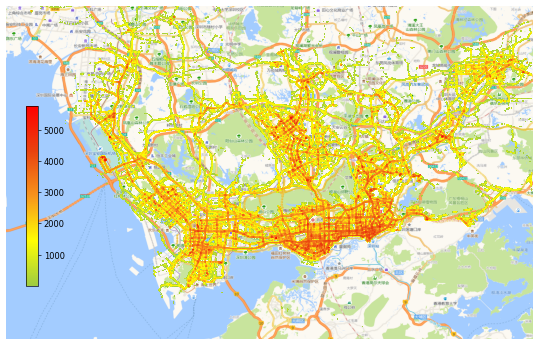

In [9]:
bounds = [113.7, 22.42, 114.3, 22.8]

# 导入绘图包
import matplotlib as mpl
import matplotlib.pyplot as plt
import plot_map
import seaborn as sns
import numpy as np

#   -- plot --
fig     = plt.figure(1,(10,10),dpi = 60)  
ax      = plt.subplot(111)
plt.sca(ax)

#  调整整体空白
fig.tight_layout(rect = (0.05,0.1,1,0.9))
# fig.tight_layout()matplotlib 提供的自动布局函数，会自动计算子图、坐标轴标签、标题的位置，调整子图间距和边距，解决标签被截断、元素重叠的问题。
# 这里通过画布对象 fig 调用，对当前画布内的所有子图生效
# rect=(left, bottom, right, top) 表各边界距画布x%宽度

# 绘制底图
plot_map.plot_map(plt,bounds,zoom = 12,style = 4)

# 手动定义一组渐变颜色，生成平滑的连续热力色色带
cmap = mpl.colors.LinearSegmentedColormap.from_list('cmap', ['#9DCC42','#FFFE03','#F7941D','#E9420E','#FF0000'], 256)
# LinearSegmentedColormap：中用于创建线性分段连续色图的核心类，支持基于多个关键色自动插值生成平滑渐变的完整色带，是自定义配色的标准底层工具
# .from\_list():可以直接从一个颜色列表快速生成连续色图，无需手动配置每个颜色节点的位置，默认在颜色之间做均匀线性插值
# camp为自定义色图的名字标识，不影响视觉效果
# 颜色列表['#9DCC42','#FFFE03','#F7941D','#E9420E','#FF0000']：这是 5 个十六进制格式的关键色，按「数值低→数值高」的顺序排列
# 浅绿#9DCC42：对应低密度区域 亮黄#FFFE03：中低密度过渡 橙色 #F7941D：中密度过渡 深红#E9420E：中高密度过渡 正红 #FF0000：对应高密度峰值
# “冷→暖” 热力图配色逻辑，颜色递进符合人眼对密度高低的视觉认知
# 256：最终色带的颜色总级数，也就是在 5 个关键色之间插值生成总共 256 个渐变色阶（默认值）足够保证颜色过渡平滑细腻，不会出现肉眼可见的色阶断层

# 绘制热力图
plt.contourf(x,y,z, levels=levels, cmap=cmap,origin = 'lower')
# x:横轴坐标数组,对应经度（Lng）序列  y:纵轴坐标数组,对应纬度（Lat）序列  z:二维数值矩阵，每个元素对应「x 列 + y 行」交叉位置的数值，对应(count)
# levels=levels：等高线的分层阈值，控制热力图的颜色分段数量
# cmap=cmap：颜色映射方案（colormap），定义「数值大小 → 颜色」的对应规则
# origin = 'lower'：指定 z 矩阵的原点对齐方式 （lower->左下角  默认upper->左上角）


plt.axis('off')
plt.xlim(bounds[0],bounds[2])
plt.ylim(bounds[1],bounds[3])

# 自定义颜色条
# 手动构建颜色 - 数值的映射对象
plt.imshow([np.exp(levels)], cmap=cmap)
# levels：基于对数变换后的计数值生成的分层阈值（先执行了z = np.log(d.values)压缩数值差异，再用np.linspace生成 levels），本身的数值是对数结果
# np.exp(levels)：对 levels 做自然指数运算，把对数尺度的阈值还原回原始的出租车 GPS 点计数量级
# []:把形状从(N,)转成(1, N)的二维数组（1 行 N 列），满足plt.imshow()要求的二维输入格式
# cmap=cmap：指定和热力图完全一致的自定义渐变色带，保证颜色条的颜色和热力图一一对应
# plt.imshow()：本意是渲染二维图像，这里传入一行的数值数组，相当于生成了一条极窄的横向色带样本，记录下「数值→颜色」的完整映射关系，供后续颜色条使用
# (常规无对数变换的场景下，更规范的写法是直接把contourf返回的cset对象传给colorbar；但那样刻度会是对数后的值，读者无法直观对应真实的出租车数量)

# 手动创建一个专属坐标轴，用来精确放置颜色条
cax = plt.axes([0.13, 0.32, 0.02, 0.3])

# 生成颜色条，并渲染到刚才创建的专属坐标轴里
plt.colorbar(cax=cax)


plt.show()

热力图绘制(seaborn-kdeplot)

In [10]:
"""
缺点：
1.由于kdeplot绘制不支持为数据点加权重，无法用先集计后绘制的方法，只能输入整个数据集绘制，如果数据量大，绘制速度极慢
2.绘制的依据为进行核密度估计后的值，这一值是抽象的只能显示相对关系，无法对应实际的物理意义
3.核密度会导致绘图精度丢失，你只能看到一坨东西在那
"""

'\n缺点：\n1.由于kdeplot绘制不支持为数据点加权重，无法用先集计后绘制的方法，只能输入整个数据集绘制，如果数据量大，绘制速度极慢\n2.绘制的依据为进行核密度估计后的值，这一值是抽象的只能显示相对关系，无法对应实际的物理意义\n3.核密度会导致绘图精度丢失，你只能看到一坨东西在那\n'

In [11]:
# 筛选范围内的数据点
data= data[(data['Lng']>bounds[0])&(data['Lng']<bounds[2])&(data['Lat']>bounds[1])&(data['Lat']<bounds[3])]

# 抽样
datasample = data.sample(10000)
# sample(10000) 默认是无放回随机抽样，即从数据里随机选 10000 个不重复的 GPS 点，返回一个新的 DataFrame
# kdeplot 是逐点计算核密度估计，数据量越大，计算量呈近似线性增长，绘制速度会非常慢。
# 10000 个样本点已经足够还原整体的空间分布趋势，同时能大幅缩短绘图时间，兼顾可视化效果和运行效率

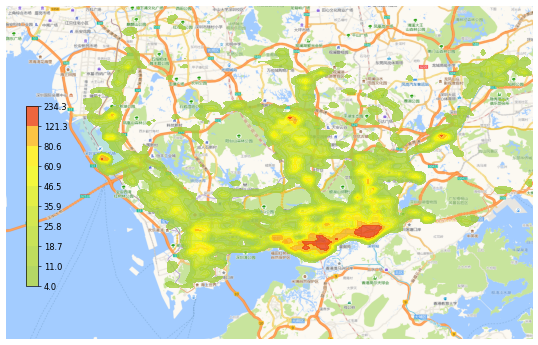

In [12]:

bounds = [113.7, 22.42, 114.3, 22.8]

# 导入绘图包
import matplotlib as mpl
import matplotlib.pyplot as plt
import plot_map
import seaborn as sns
import numpy as np

#   -- plot --
fig     = plt.figure(1,(10,10),dpi = 60)  
ax      = plt.subplot(111)
plt.sca(ax)
fig.tight_layout(rect = (0.05,0.1,1,0.9))#调整整体空白

# 绘制底图
plot_map.plot_map(plt,bounds,zoom = 12,style = 4)

# colorbar的数据
import matplotlib
cmap = matplotlib.colors.LinearSegmentedColormap.from_list('cmap', ['#9DCC42','#FFFE03','#F7941D','#E9420E','#FF0000'], 256)


plt.axis('off')
plt.xlim(bounds[0],bounds[2])
plt.ylim(bounds[1],bounds[3])

# 定义colorbar位置
cax = plt.axes([0.13, 0.32, 0.02, 0.3])
# 绘制热力图
sns.kdeplot(x=datasample['Lng'], y=datasample['Lat'],
            alpha = 0.8, # 透明度
            gridsize = 100, # 绘图精细度，越高越慢
            bw_method = 0.03,    # 高斯核大小（经纬度），越小越精细
            fill=True, # 是否填充区域（等高线之间的区域会用对应颜色填充，形成完整的热力填充效果）
            thresh=0.05,   # 密度低于 5% 最大值的最外层区域不会填充颜色，边缘干净不盖底图
            cbar=True, # 是否显示颜色条
            cmap = cmap, # 颜色映射
            ax = ax, # 指定绘图位置
            cbar_ax=cax # 指定colorbar位置
           )

plt.show()